# GB wind & solar forecast error analysis

This notebook uses the same snapshot and selection logic as the web app (`monitor/`), so its numbers match the UI.
- **Error = actual − forecast.** A negative error means wind or solar under-delivered, and the shortfall must be bought.
- **Gate** = the latest forecast published *strictly before* 11:00 UK time on D-1 (the GB day-ahead auction).

Sections:
1. January 2026, the original brief
2. Error vs lead time
3. Scope check: why the forecast looks biased
4. Twelve months: seasonality, and how well the out-of-sample bands are calibrated
5. Backtest of MW-to-buy
6. Solar and DGWS
7. Cost & risk: price link, band models, purchase policy, flags
8. Recommendation

In [1]:
import sys; sys.path.insert(0, "..")
from datetime import date
import pandas as pd, matplotlib.pyplot as plt
from monitor import core
from monitor.data import load, latest_revision, rows
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "grid.alpha": .3})
D = load()
wind_h, windfor, _ = D["sources"]["windfor"]

def frame(source, mode="gate", h=0):
    a, f, night = D["sources"][source]
    df = pd.DataFrame(core.pairs(a, f, mode, h, night_mw=night))
    df["t"] = pd.to_datetime(df.t); df["month"] = df.t.dt.strftime("%Y-%m")
    return df.set_index("t")

def summary(e, actual):
    return pd.Series({"n": len(e), "MAE": e.abs().mean(), "RMSE": (e**2).mean()**.5, "bias": e.mean(),
                      "P10": e.quantile(.1), "P90": e.quantile(.9), "nMAE %": 100 * e.abs().mean() / actual.mean()}).round(1)

gate = frame("windfor")
print("hours compared:", len(gate), "|", gate.index.min().date(), "→", gate.index.max().date())

hours compared: 9376 | 2025-10-01 → 2026-10-27


## 1. January 2026 (original brief)

In [2]:
jan = gate[gate.month == "2026-01"]
print(jan.publishTime.str[11:16].value_counts().to_dict(), "| lead", jan.leadH.min(), "–", jan.leadH.max(), "h")
summary(jan.error, jan.actual)

{'09:30': 744} | lead 14.5 – 37.5 h


n          744.0
MAE       2122.8
RMSE      2616.7
bias     -1840.3
P10      -4312.4
P90        489.0
nMAE %      18.3
dtype: float64

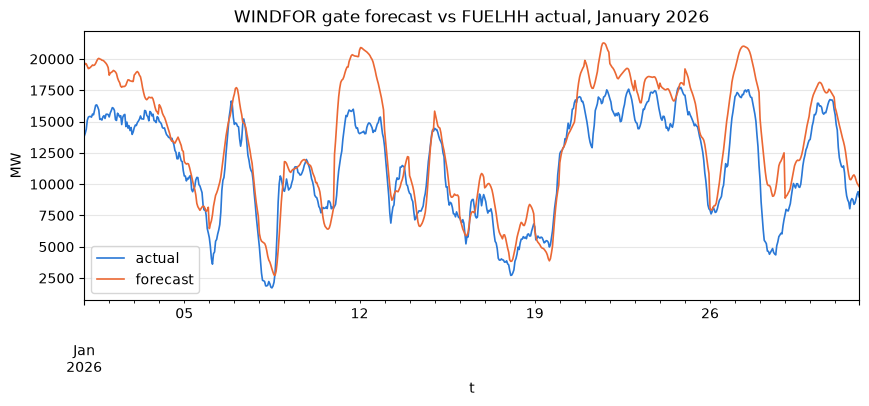

In [3]:
ax = jan[["actual", "forecast"]].plot(color=["#2a78d6", "#eb6834"], lw=1.2)
ax.set_ylabel("MW"); ax.set_title("WINDFOR gate forecast vs FUELHH actual, January 2026");

## 2. Error vs lead time (January 2026)
Horizon mode takes the latest publish at least H hours before the target.

h,0,6,12,18,24,30,36,42,48
mae,1800,1881,1907,1990,2064,2204,2270,2320,2387
rmse,2287,2357,2384,2459,2524,2655,2758,2847,2939
bias,-1593,-1684,-1704,-1791,-1855,-1898,-1951,-1940,-1868
n,744,744,744,744,744,744,744,744,589


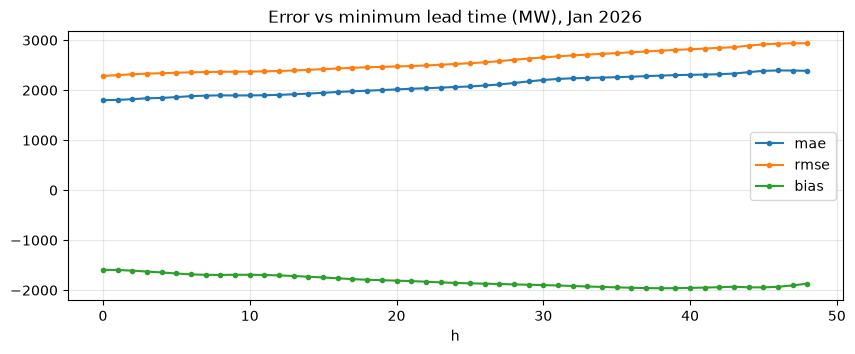

In [4]:
curve = pd.DataFrame(core.horizon_curve(wind_h, windfor, core.ts("2026-01-01T00:00:00Z"), core.ts("2026-01-31T23:00:00Z"))).set_index("h")
curve[["mae", "rmse", "bias"]].plot(marker=".", title="Error vs minimum lead time (MW), Jan 2026"); curve.iloc[::6].round(0).T

Error grows slowly with lead time: about 1.8 GW MAE at 0h, rising to about 2.4 GW at 48h. But even the freshest forecast has a large **bias**, so the next question is where that bias comes from.

## 3. Scope check: why WINDFOR looks biased against FUELHH

In [5]:
ag = latest_revision(rows("agws"))
agws_wind = core.hourly({t: v + ag["wind_off"][t] for t, v in ag["wind_on"].items() if t in ag["wind_off"]})
both = pd.DataFrame({"FUELHH": pd.Series(wind_h), "AGWS": pd.Series(agws_wind)}).dropna()
print(f"mean FUELHH {both.FUELHH.mean():.0f} MW, AGWS {both.AGWS.mean():.0f} MW, gap {(both.AGWS - both.FUELHH).mean():.0f} MW")
dg = D["sources"]["dgws_wind"][1]
grid = {}
for fname, fidx, mode in [("WINDFOR (gate)", windfor, "gate"), ("DGWS (day-ahead run)", dg, "dayahead")]:
    for aname, act in [("vs FUELHH", wind_h), ("vs AGWS", agws_wind)]:
        c = core.core_stats(core.pairs(act, fidx, mode))
        grid[(fname, aname)] = f"MAE {c['mae']:,} / bias {c['bias']:+,}"
pd.Series(grid).unstack()

mean FUELHH 8957 MW, AGWS 10474 MW, gap 1516 MW


,vs AGWS,vs FUELHH
DGWS (day-ahead run),"MAE 2,302 / bias -2,082","MAE 3,597 / bias -3,555"
WINDFOR (gate),"MAE 1,353 / bias +39","MAE 1,797 / bias -1,448"


**Finding.** AGWS wind (which includes an estimate of embedded wind) runs about **1.5 GW above** FUELHH on average over 12 months (FUELHH is transmission-metered only).

Scored against AGWS, WINDFOR's bias almost disappears. So WINDFOR forecasts a **wider wind scope** than FUELHH measures. Most of the apparent January over-forecast is this scope mismatch, not weather error. This supersedes the curtailment hypothesis from the MVP notebook.

**Why it matters for buying.** National Demand (NDF) already nets off embedded generation, so the residual the desk must buy is `NDF − transmission wind`. The app corrects WINDFOR with its trailing median error against **FUELHH**, which re-scales it to transmission scope before subtracting it from NDF. Section 5 backtests this.

## 4. Twelve months: seasonality and band calibration

,MAE,RMSE,bias,P10,P90,nMAE %
month,,,,,,
2025-10,2185.0,2825.0,-1793.0,-4775.0,750.0,24.0
2025-11,1883.0,2375.0,-1009.0,-3874.0,1803.0,17.0
2025-12,2010.0,2563.0,-1405.0,-4375.0,1092.0,18.0
2026-01,2123.0,2617.0,-1840.0,-4312.0,489.0,18.0
2026-02,1683.0,2029.0,-1309.0,-3115.0,580.0,15.0
2026-03,2086.0,2522.0,-1958.0,-3985.0,190.0,21.0
2026-04,1908.0,2592.0,-1557.0,-4754.0,755.0,24.0
2026-05,1160.0,1469.0,-985.0,-2430.0,332.0,19.0
2026-06,1462.0,1882.0,-1174.0,-3212.0,553.0,22.0


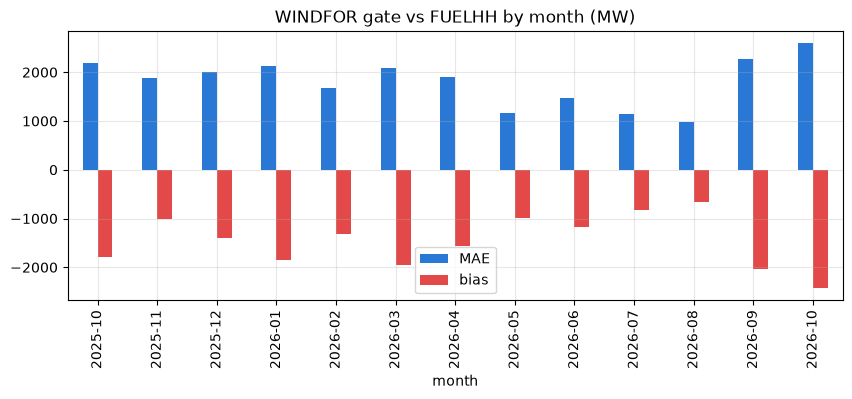

In [6]:
monthly = gate.groupby("month").apply(lambda g: summary(g.error, g.actual)).drop(columns="n")
monthly[["MAE", "bias"]].plot.bar(title="WINDFOR gate vs FUELHH by month (MW)", color=["#2a78d6", "#e34948"]); monthly.round(0)

In [7]:
by_day = core.errors_by_day(core.pairs(wind_h, windfor, "gate"))
bands = {d: core.rolling_band(by_day, date.fromisoformat(d)) for d in gate.day.unique()}
g = gate.assign(p10=gate.day.map(lambda d: (bands[d] or {}).get("p10")), p90=gate.day.map(lambda d: (bands[d] or {}).get("p90"))).dropna()
cov10 = (g.actual >= g.forecast + g.p10).groupby(g.month).mean()
cov90 = (g.actual <= g.forecast + g.p90).groupby(g.month).mean()
cal = pd.DataFrame({"actual ≥ P10 line (target 90%)": cov10, "actual ≤ P90 line (target 90%)": cov90}).round(3) * 100
print(f"overall: {100*(g.actual >= g.forecast + g.p10).mean():.1f}% of hours at or above the conservative P10 line")
cal

overall: 88.4% of hours at or above the conservative P10 line


,actual ≥ P10 line (target 90%),actual ≤ P90 line (target 90%)
month,,
2025-10,99.0,70.5
2025-11,95.0,84.2
2025-12,86.0,90.2
2026-01,88.6,95.3
2026-02,92.9,89.1
2026-03,81.2,92.2
2026-04,89.9,84.6
2026-05,92.3,93.3
2026-06,83.8,89.6


The trailing 30-day band only uses errors known at the gate (days D-31…D-2), so this is a genuine **out-of-sample** check. If a month falls well below 90%, that month's errors were worse than the previous 30 days predicted. This tends to happen when the regime changes (for example, the season turning).

## 5. Backtest: MW-to-buy (portfolio share 5%)
Uses the app's champion residual band; expected = P50 of need, conservative = P90.

386 days | daily MWh error (actual − expected): MAE 1287, bias -109
conservative covered actual need on 95% of days; average buffer 2711 MWh/day


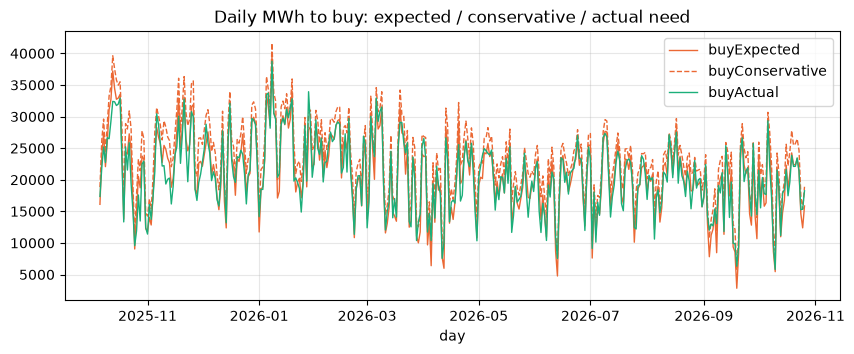

In [8]:
from monitor.risk import Risk
R = Risk(D)
share, lam = 0.05, 0.5
days = sorted(R.rows_by_day)
recs = []
for d in days:
    dec = R.decision(d, share, lam)
    t = dec["totals"]
    if dec["bandModel"]["name"] and None not in (t["buyExpected"], t["buyConservative"], t["buyActual"]):
        recs.append({"day": d, **{k: t[k] for k in ("buyExpected", "buyConservative", "buyActual")}})
bt = pd.DataFrame(recs).set_index("day")
bt["err_expected"] = bt.buyActual - bt.buyExpected
print(f"{len(bt)} days | daily MWh error (actual − expected): MAE {bt.err_expected.abs().mean():.0f}, bias {bt.err_expected.mean():+.0f}")
print(f"conservative covered actual need on {100*(bt.buyConservative >= bt.buyActual).mean():.0f}% of days; "
      f"average buffer {(bt.buyConservative - bt.buyExpected).mean():.0f} MWh/day")
bt[["buyExpected", "buyConservative", "buyActual"]].plot(title="Daily MWh to buy: expected / conservative / actual need",
                                                         color=["#eb6834", "#eb6834", "#1baf7a"], style=["-", "--", "-"], lw=1);

## 6. Solar and DGWS

In [9]:
sol = frame("dgws_solar", "dayahead")
print("DGWS solar day-ahead run (published ~16:45 UTC D-1, after the gate), daylight half-hours only")
display(summary(sol.error, sol.actual))
sol.groupby("month").apply(lambda g: summary(g.error, g.actual))[["MAE", "bias", "nMAE %"]].round(0)

DGWS solar day-ahead run (published ~16:45 UTC D-1, after the gate), daylight half-hours only


n         8981.0
MAE        496.2
RMSE       858.9
bias      -158.9
P10       -890.0
P90        626.0
nMAE %      11.6
dtype: float64

,MAE,bias,nMAE %
month,,,
2025-10,644.0,-280.0,26.0
2025-11,438.0,278.0,20.0
2025-12,330.0,-28.0,21.0
2026-01,400.0,3.0,22.0
2026-02,416.0,-172.0,20.0
2026-03,752.0,-149.0,18.0
2026-04,964.0,40.0,16.0
2026-05,471.0,8.0,9.0
2026-06,496.0,-484.0,10.0


- **Timing.** DGWS (ENTSO-E day-ahead) publishes its forecast for day D at about 16:45 UTC on D-1, after the 11:00 auction gate. The 07:00 and 11:00 runs cover the same day (intraday). So DGWS can be scored for accuracy, but it can't feed a day-ahead bid. Only WINDFOR (09:30) and NDF (08:45) arrive in time.
- **Solar does not enter MW-to-buy.** It is mostly embedded and already netted inside National Demand.
- **Data quality.** AGWS has gaps in some summer months (about 28 of 48 periods per day in June 2026), so metrics there use fewer points. The largest solar errors (about −13.5 GW on 26 Apr 2026) come from a DGWS forecast of about 25 GW. That is above GB's plausible solar output, but it is genuine source data and has been kept.

## 7. Cost & risk of the purchase decision

In [10]:
# premise: do national forecast errors move the imbalance-vs-day-ahead spread?
pts = [(r["e"], D["sip"][r["t"]] - D["mid"][r["t"]]) for x in days for r in R.rows_by_day[x]
       if r["e"] is not None and r["t"] in D["sip"] and r["t"] in D["mid"]]
sp = pd.DataFrame(pts, columns=["e", "spread"])
same = sum(abs(D["sip"][t] - D["mid"][t]) < 0.01 for t in D["sip"] if t in D["mid"]) / sum(t in D["mid"] for t in D["sip"])
print(f"corr(residual error, imbalance − APX) = {sp.e.corr(sp.spread):.3f} over {len(sp):,} half-hours; "
      f"mean spread £{sp.spread.mean():.2f}/MWh; imbalance price == APX in {100*same:.0f}% of periods")
sp.groupby(pd.cut(sp.e, [-1e9, -2000, -500, 500, 2000, 1e9])).spread.agg(["mean", "median", "count"]).round(1)

corr(residual error, imbalance − APX) = 0.065 over 18,740 half-hours; mean spread £0.57/MWh; imbalance price == APX in 14% of periods


,mean,median,count
e,,,
"(-1000000000.0, -2000.0]",-2.8,-7.8,760
"(-2000.0, -500.0]",-2.6,-2.6,2329
"(-500.0, 500.0]",-0.3,-0.0,3327
"(500.0, 2000.0]",1.1,0.0,5459
"(2000.0, 1000000000.0]",2.0,0.0,6865


The imbalance price barely reacts to *this* national forecast error (correlation about 0.06), because it is set by the whole system's balancing position. The spread is slightly positive when more was needed than forecast, and slightly negative when less was. The real money is in the **tails**: price spikes when short, and crashes when long.

In [11]:
models = pd.DataFrame(R.report(days[0], days[-1], share, lam)["models"]).set_index("model")
models[["pinball", "championDays"]].join(pd.DataFrame(models.coverage.tolist(), index=models.index)[["0.1", "0.5", "0.9"]])

,pinball,championDays,0.1,0.5,0.9
model,,,,,
wind_only,548,0,0.160,0.485,0.851
combined,542,8,0.115,0.500,0.886
conditional,481,381,0.117,0.513,0.894


**Uncertainty models.** These are out-of-sample: each day's band uses only days up to D-2.
- The **conditional** model (residual error by wind-forecast tercile × evening peak) has the lowest pinball loss and coverage closest to nominal.
- The old **wind-only** band under-covers: about 85% instead of 90% at P90. It ignores demand-forecast error, and wind error grows with the wind level.

whole-range frontier, λ = 0.5 → recommended 0.7


,meanCost,cvar95,pShort,shortMWh,days
q,,,,,
0.50,3530,52011,0.485,858,386
0.60,3239,50572,0.393,630,386
0.70,2952,50111,0.298,435,386
0.80,2768,52608,0.202,266,386
0.90,2615,62483,0.104,129,386
0.95,2475,73186,0.055,67,386


,total,meanDaily,cvar95,objective,days
p50,877481,4902,68645,39224,179
recommended,877481,4902,68645,39224,179
p90,888205,4962,63672,36798,179


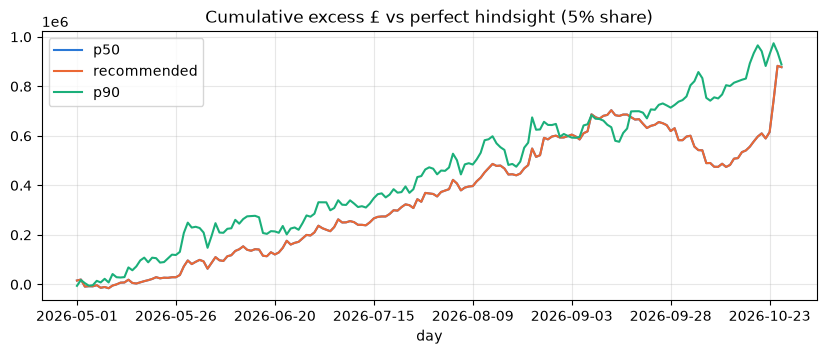

In [12]:
rep = R.report(days[0], days[-1], share, lam)
fr = pd.DataFrame(rep["frontier"]["rows"]).set_index("q")
print("whole-range frontier, λ =", lam, "→ recommended", rep["frontier"]["q"])
display(fr)
display(pd.DataFrame(rep["realised"]).T)
cum = pd.DataFrame(rep["cumulative"]).set_index("day")
cum[["p50", "recommended", "p90"]].plot(title="Cumulative excess £ vs perfect hindsight (5% share)", color=["#2a78d6", "#eb6834", "#1baf7a"]);

In [13]:
# sensitivity: which purchase level would a whole-range λ pick in hindsight?
display(pd.Series({l: R.frontier(days, share, l)["q"] for l in (0, 0.1, 0.25, 0.5, 1, 2)}, name="hindsight q").to_frame().T)
# the live policy: each month uses only history before it (expanding window, >= 180 priced days)
pd.DataFrame([{"month": m, **{k: p[k] for k in ("q", "trackDays", "validated")}, **(p["objective"] or {})}
              for m in sorted({d.replace(day=1) for d in days}) if (p := R.policy(m, share, lam))]).set_index("month")

,0.00,0.10,0.25,0.50,1.00,2.00
hindsight q,0.95,0.7,0.7,0.7,0.7,0.7


,q,trackDays,validated,policy,p50,p90
month,,,,,,
2026-05-01,0.5,0,False,NaN,NaN,NaN
2026-06-01,0.5,30,False,NaN,NaN,NaN
2026-07-01,0.5,60,True,17165.0,17165.0,31746.0
2026-08-01,0.5,91,True,20650.0,20650.0,32232.0
2026-09-01,0.5,122,True,27253.0,27253.0,36924.0
2026-10-01,0.5,152,True,27991.0,27991.0,36751.0


**Purchase policy.**
- A rolling 90-day choice was tried first and **lost to both fixed rules** out-of-sample. Its CVaR95 rests on about 5 days, so it chased noise.
- The app now uses an expanding-window policy, re-chosen monthly. It is only labelled "recommended" when its own track record matches or beats always-P50 and always-P90 on the same objective.
- On this data the policy settles on **P50**. Over its live months, P50 and P90 are within about 1% on total cost and differ mainly in the tail. **The £ case for a systematic buffer is weak so far.** Re-check this as history accumulates.

In [14]:
pd.DataFrame(rep["flags"]).set_index("key")

,maeFlagged,costFlagged,maeOther,costOther,daysFlagged,daysOther
key,,,,,,
revision,2417,612,1736,5266,14,165
ramp,2340,5349,1696,4826,26,153
margin,1438,415,1829,5404,18,161


**Flags.**
- **Ramp** days (largest hourly change in the forecast) are clearly riskier, with higher error and higher excess £.
- **Revision** days are mildly riskier.
- **Tight-margin** days were *calmer* in this sample (high-pressure, low-wind and well-forecast). So that flag is informational rather than a buffer trigger.

## 8. Recommendation
1. **Plan against the conditional residual band.** It covers demand and wind error together, by wind level and peak. It is the best-calibrated model (P90 coverage about 89% vs 85% for the old wind-only band). Its median re-scales WINDFOR to the transmission wind that offsets National Demand.
2. **Treat the buffer as a risk-appetite choice, not a saving.** In £ terms P50 and P90 are close on average; the monthly policy (Risk & cost tab) shows which one the chosen λ favours, and whether it has earned the label "recommended".
3. **Watch ramp days.** Days with a large hourly ramp in the gate forecast had about 20% higher error and about 70% higher excess £.
4. **Sizing.** With the conservative quantity (P90 of the conditional residual band), the buy covered the realised need on 95% of 386 days, for an average buffer of about 2.7 GWh/day at a 5% share. The expected (P50) quantity was off by 1.3 GWh/day on average (MAE), with almost no bias (−0.1 GWh). By comparison, the old wind-only band put actual wind above its P10 line in only 88% of hours.
5. **Use the 09:30 D-1 WINDFOR publish.** Lead time adds error only slowly; the scope/bias effect is far larger. DGWS arrives too late to trade on.

Caveats: 13 months of history; FUELHH vs AGWS scope is inferred from the data, not from a documented definition; the portfolio share is a proxy for the client's real demand.